# GDP Prediction — ML (Polynomial, XGBoost) & DL (LSTM + Transformer) Using PyTorch



## 1. Setup: imports, device, seeds


In [1]:
!pip install -q xgboost joblib

In [2]:
import os, random, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import StandardScaler, MinMaxScaler, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

import xgboost as xgb

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import re

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

Using device: cpu


In [3]:
# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)

## 2. Metrics utilities
We use MAE, RMSE, and R².

In [4]:
def mae(y_true, y_pred):
    return mean_absolute_error(y_true, y_pred)
def rmse(y_true, y_pred):
    return float(math.sqrt(mean_squared_error(y_true, y_pred)))
def r2(y_true, y_pred):
    return r2_score(y_true, y_pred)
def evaluate_metrics(y_true, y_pred):
    return {"MAE": mae(y_true,y_pred), "RMSE": rmse(y_true,y_pred), "R2": r2(y_true,y_pred)}

## 3. Load Data & visualize GDP over years
We preserve the original Year label (e.g. `2024-25`) as `Year_label` and also extract a numeric year for ordering. The plot uses `Year_label` with cleaned formatting like `2024_25`.

Using CSV: /content/final GDP Dataset - Copy.csv


,Year,Private Final Consumption Expenditure__Constant Prices,Government Final Consumption Expenditure__Constant Prices,Gross Fixed Capital Formation__Constant Prices,Changes in Stocks__Constant Prices,Exports of Goods and Services__Constant Prices,Import of Goods and Services__Constant Prices,Gross Domestic Product__Constant Prices,Year_label,Year_num
0,2024_25,7.20,2.28,7.06,4.46,6.34,-3.67,6.49,2024_25,2024
1,2023_24,5.56,8.14,8.78,53.44,2.20,13.75,9.19,2023_24,2023
2,2022_23,7.47,4.30,8.45,24.33,10.32,8.92,7.61,2022_23,2022
3,2021_22,11.68,0.02,17.52,525.39,29.60,22.09,9.69,2021_22,2021
4,2020_21,-5.29,-0.77,-7.10,-76.40,-6.96,-12.62,-5.78,2020_21,2020


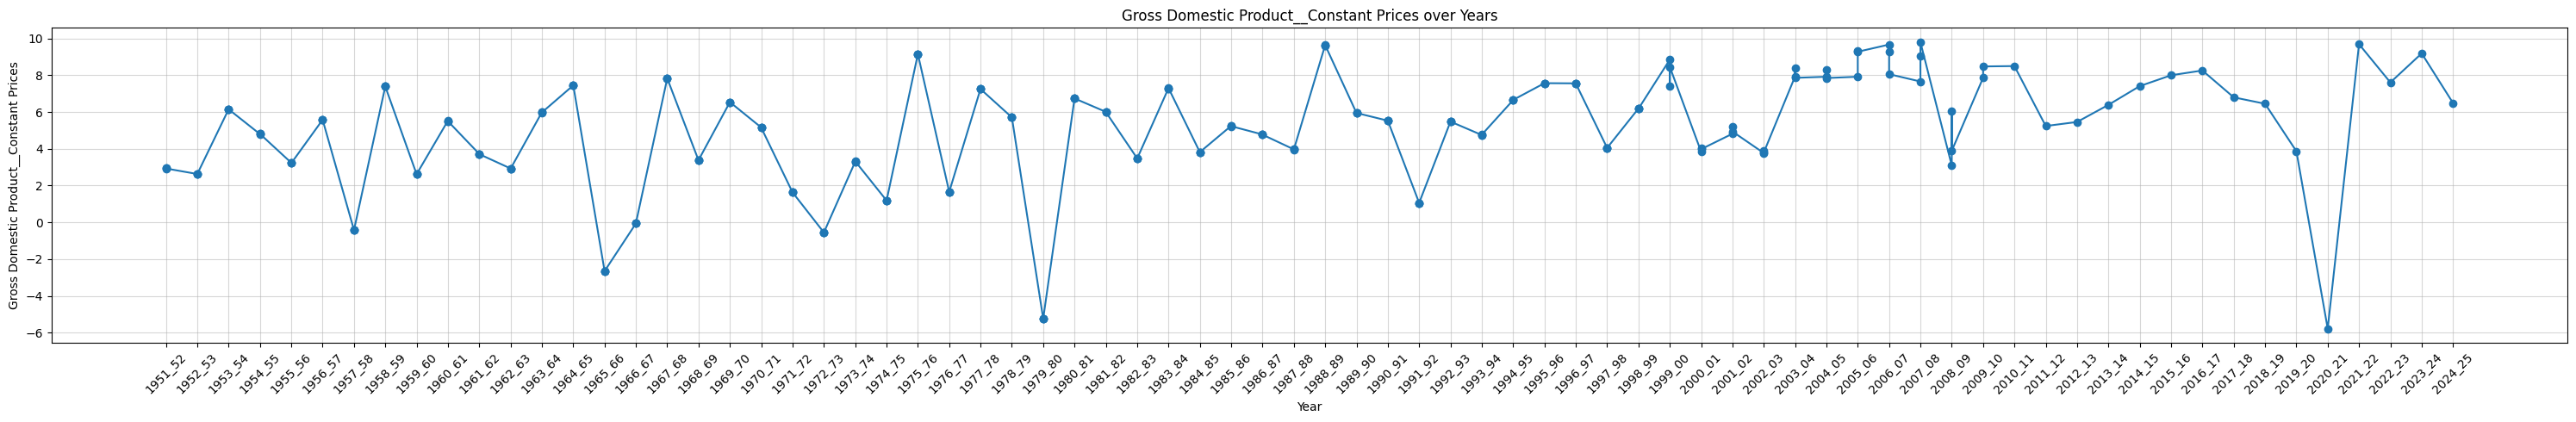

In [5]:
expected_path = '/content/final GDP Dataset - Copy.csv'
local_path = '/content/final GDP Dataset - Copy.csv'

csv_path = None
if Path(expected_path).exists():
    csv_path = expected_path
elif Path(local_path).exists():
    csv_path = local_path
else:
    try:
        from google.colab import files
        print("Please upload the CSV file (choose 'final GDP Dataset - Copy.csv') — a file dialog will open.")
        uploaded = files.upload()
        csv_path = next(iter(uploaded.keys()))
    except Exception as e:
        raise RuntimeError("CSV not found. Please upload `final GDP Dataset - Copy.csv` to the Colab environment.") from e

print('Using CSV:', csv_path)
df = pd.read_csv(csv_path)

df['Year_label'] = df['Year'].astype(str)
df['Year_label'] = df['Year_label'].str.replace('-', '_').str.replace('/', '_').str.strip()

df['Year_num'] = df['Year_label'].str.extract(r'(\d{4})')
df['Year_num'] = pd.to_numeric(df['Year_num'], errors='coerce')

if df['Year_num'].isna().any():
    df['Year_num'] = range(len(df))

target_col = 'Gross Domestic Product__Constant Prices'
if target_col not in df.columns:
    raise RuntimeError(f"Target column '{target_col}' not found. Columns: {df.columns.tolist()}")

display(df.head())

def extract_year_int(s):
    m = re.search(r"(19|20)\d{2}", str(s))
    return int(m.group(0)) if m else None

df_model = df.copy()
year_cols = [c for c in df.columns if 'year'.lower().strip() in c.lower()]
YEAR_COL = year_cols[0] if year_cols else None

plot_df = df_model.copy()
plot_df["_yr"] = plot_df[YEAR_COL].apply(extract_year_int)
plot_df = plot_df.sort_values("_yr")

target_candidates = [c for c in df_model.columns if ('gross domestic' in c.lower() or 'gdp' in c.lower())]
TARGET_FOR_PLOT = target_candidates[0] if target_candidates else df_model.columns[-1]

plt.figure(figsize=(30,5))
plt.plot(plot_df[YEAR_COL], plot_df[TARGET_FOR_PLOT], marker='o', linestyle='-')
plt.xticks(rotation=45)
plt.title(f"{TARGET_FOR_PLOT} over Years")
plt.xlabel("Year")
plt.ylabel(TARGET_FOR_PLOT)
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

## 4. ML part: train/test 80/20
This section:
- Splits the data (first 80% years for training, last 20% for testing).
- Standard-scales ML features.
- Trains Polynomial Regression (degree=2 + Ridge) and XGBoost.
- Evaluates and prints MAE, RMSE, R² for both models.

In [24]:
# Prepare features and target
feature_cols = [c for c in df.columns if c not in ['Year','Year_label','Year_num', target_col]]
print('Features:', feature_cols)
X = df[feature_cols].values
y = df[target_col].values

# 80/20 split
n = len(df)
split_idx = int(n * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]
years_ml = df['Year_label'].iloc[split_idx:].values
print(f'Train size: {len(y_train)}, Test size: {len(y_test)}')

Features: ['Private Final Consumption Expenditure__Constant Prices', 'Government Final Consumption Expenditure__Constant Prices', 'Gross Fixed Capital Formation__Constant Prices', 'Changes in Stocks__Constant Prices', 'Exports of Goods and Services__Constant Prices', 'Import of Goods and Services__Constant Prices']
Train size: 152, Test size: 39


### 4.1 Standard scaling for ML features
We scale features before training ML models.

In [7]:
scaler_ml = StandardScaler()
X_train_scaled = scaler_ml.fit_transform(X_train)
X_test_scaled = scaler_ml.transform(X_test)
joblib.dump(scaler_ml, 'scaler_ml.joblib')

['scaler_ml.joblib']

### 4.2 Polynomial Regression (degree=2) + Ridge

In [8]:
poly_pipeline = Pipeline([('poly', PolynomialFeatures(degree=2, include_bias=False)),
                          ('scaler', StandardScaler()), ('ridge', Ridge(alpha=1.0, random_state=SEED))])
poly_pipeline.fit(X_train, y_train)
poly_pred = poly_pipeline.predict(X_test)
poly_train_pred = poly_pipeline.predict(X_train)
metrics_poly_test = evaluate_metrics(y_test, poly_pred)
metrics_poly_train = evaluate_metrics(y_train, poly_train_pred)
print('Polynomial TEST metrics:', metrics_poly_test)
print('Polynomial TRAIN metrics:', metrics_poly_train)
joblib.dump(poly_pipeline, 'polynomial_pipeline.joblib')

Polynomial TEST metrics: {'MAE': 1.0413434645494315, 'RMSE': 1.2567815018059105, 'R2': 0.8346471992641507}
Polynomial TRAIN metrics: {'MAE': 0.8760661875603329, 'RMSE': 1.1330980894717593, 'R2': 0.8579840046470513}


['polynomial_pipeline.joblib']

Polynomial: FULL ML test years (len = 39 )


,Model,RMSE_train,RMSE_test,MAE,RMSE,R2
0,Polynomial Regression,1.1331,1.2568,1.0413,1.2568,0.8346


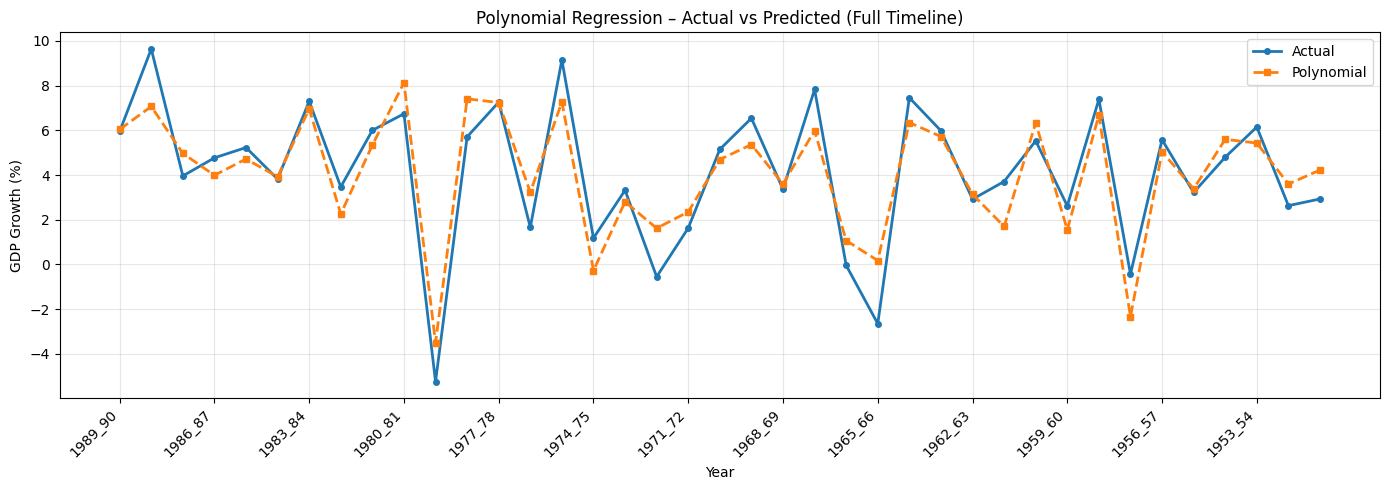

In [26]:
poly_train_rmse = rmse(y_train, poly_train_pred)
poly_test_rmse_full = rmse(y_test, poly_pred)

comparison_poly = pd.DataFrame([{
    'Model': 'Polynomial Regression',
    'RMSE_train': round(poly_train_rmse, 4),
    'RMSE_test': round(poly_test_rmse_full, 4),
    **evaluate_metrics(y_test, poly_pred)
}])

print("Polynomial: FULL ML test years (len =", len(years_ml), ")")
display(comparison_poly)
comparison_poly.to_csv('poly_full_years.csv', index=False)

# Actual vs Predicted (separate wide figure)
plt.figure(figsize=(14,5))
plt.plot(years_ml, y_test, 'o-', label='Actual', linewidth=2, markersize=4)
plt.plot(years_ml, poly_pred, 's--', label='Polynomial', linewidth=2, markersize=4)

step = 3  # show every 3rd year label to reduce clutter
plt.xticks(range(0, len(years_ml), step),
           years_ml[::step],
           rotation=45, ha='right')

plt.xlabel('Year')
plt.ylabel('GDP Growth (%)')
plt.title('Polynomial Regression – Actual vs Predicted (Full Timeline)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('poly_full_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

### 4.3 XGBoost (baseline hyperparameters)

In [27]:
xgb_model = xgb.XGBRegressor(objective='reg:squarederror', random_state=SEED,
                             n_estimators=200, learning_rate=0.05, max_depth=4, n_jobs=-1)
xgb_model.fit(X_train_scaled, y_train)
xgb_pred = xgb_model.predict(X_test_scaled)
xgb_train_pred = xgb_model.predict(X_train_scaled)
metrics_xgb_test = evaluate_metrics(y_test, xgb_pred)
metrics_xgb_train = evaluate_metrics(y_train, xgb_train_pred)
print('XGBoost TEST metrics:', metrics_xgb_test)
print('XGBoost TRAIN metrics:', metrics_xgb_train)
joblib.dump(xgb_model, 'xgboost_model.joblib')

XGBoost TEST metrics: {'MAE': 0.4952, 'RMSE': np.float64(0.7599), 'R2': 0.9396}
XGBoost TRAIN metrics: {'MAE': 0.1092, 'RMSE': np.float64(0.1615), 'R2': 0.9971}


['xgboost_model.joblib']

XGBoost: FULL ML test years (len = 39 )


,Model,RMSE_train,RMSE_test,MAE,RMSE,R2
0,XGBoost,0.1615,0.7599,0.4952,0.7599,0.9396


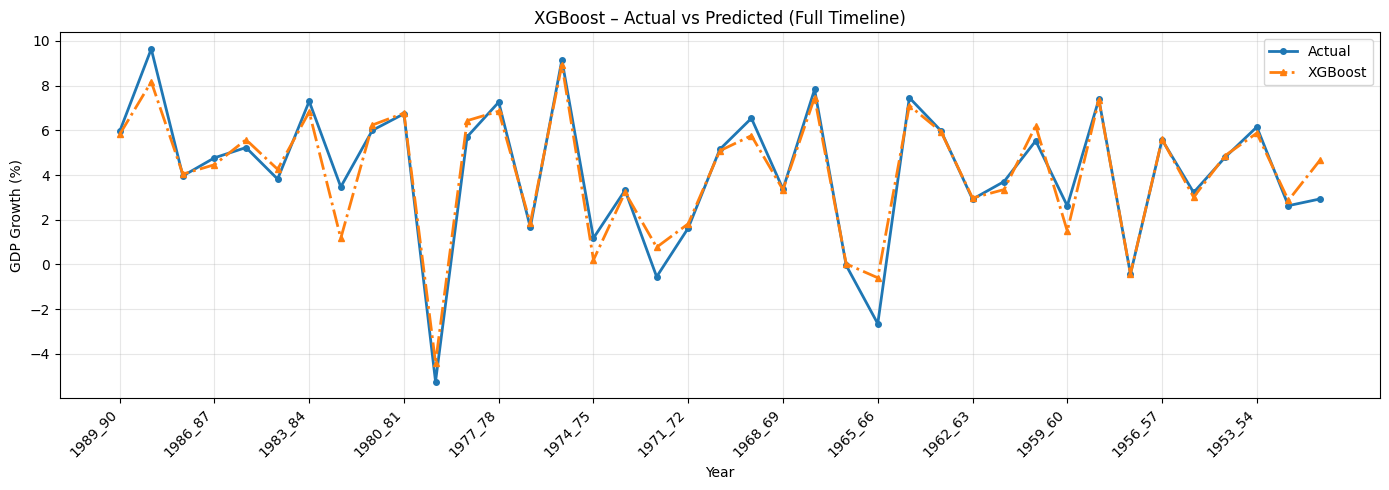

In [28]:
# ---------- XGBOOST (FULL ML TEST YEARS) ----------
xgb_train_rmse = rmse(y_train, xgb_train_pred)
xgb_test_rmse_full = rmse(y_test, xgb_pred)

comparison_xgb = pd.DataFrame([{
    'Model': 'XGBoost',
    'RMSE_train': round(xgb_train_rmse, 4),
    'RMSE_test': round(xgb_test_rmse_full, 4),
    **evaluate_metrics(y_test, xgb_pred)
}])

print("XGBoost: FULL ML test years (len =", len(years_ml), ")")
display(comparison_xgb)
comparison_xgb.to_csv('xgb_full_years.csv', index=False)

# Actual vs Predicted
plt.figure(figsize=(14,5))
plt.plot(years_ml, y_test, 'o-', label='Actual', linewidth=2, markersize=4)
plt.plot(years_ml, xgb_pred, '^-.', label='XGBoost', linewidth=2, markersize=4)

step = 3
plt.xticks(range(0, len(years_ml), step),
           years_ml[::step],
           rotation=45, ha='right')

plt.xlabel('Year')
plt.ylabel('GDP Growth (%)')
plt.title('XGBoost – Actual vs Predicted (Full Timeline)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('xgb_full_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

## 5. DL prepscaler

We will:
- Fit a feature scaler (MinMax) on features for DL inputs.
- Fit a target-only scaler (MinMax) on the GDP target for safe inverse transforms.

In [29]:
FEATURE_SCALER = MinMaxScaler()
TARGET_SCALER = MinMaxScaler()

features_all = df[feature_cols].values.astype(np.float32)
target_all = df[target_col].values.reshape(-1,1).astype(np.float32)

features_scaled_all = FEATURE_SCALER.fit_transform(features_all)
target_scaled_all = TARGET_SCALER.fit_transform(target_all)

joblib.dump(FEATURE_SCALER, 'scaler_features_dl.joblib')
joblib.dump(TARGET_SCALER, 'scaler_target_dl.joblib')

['scaler_target_dl.joblib']

### 5.1 Create sequences (sliding window)
We create sequences of length `LOOKBACK` (default 5). Each sample's input is previous `LOOKBACK` rows of features and target is the GDP of the next year.

In [30]:
LOOKBACK = 5

X_seq = []; y_seq = []

for i in range(LOOKBACK, len(df)):
    X_seq.append(features_scaled_all[i-LOOKBACK:i, :])
    y_seq.append(target_scaled_all[i,0])

X_seq = np.array(X_seq); y_seq = np.array(y_seq)
n_seq = X_seq.shape[0]; split_seq = int(n_seq*0.8)
X_train_dl, X_test_dl = X_seq[:split_seq], X_seq[split_seq:]
y_train_dl, y_test_dl = y_seq[:split_seq], y_seq[split_seq:]

years_dl = df['Year_label'].iloc[LOOKBACK + split_seq : LOOKBACK + split_seq + len(y_test_dl)].values

print("Sequence shapes:", X_seq.shape, y_seq.shape)
print(f"DL train shapes: {X_train_dl.shape}, DL test shapes: {X_test_dl.shape}")

Sequence shapes: (186, 5, 6) (186,)
DL train shapes: (148, 5, 6), DL test shapes: (38, 5, 6)


### 5.2 PyTorch Dataset & DataLoader
Create a small Dataset wrapper and DataLoader for training.

In [31]:
class SeqDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
    def __len__(self): return len(self.X)
    def __getitem__(self, idx): return self.X[idx], self.y[idx]

BATCH_SIZE = 8
train_loader = DataLoader(SeqDataset(X_train_dl, y_train_dl), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(SeqDataset(X_test_dl, y_test_dl), batch_size=BATCH_SIZE, shuffle=True)

### 5.3 LSTM Model
Bidirectional LSTM -> Dense layers -> Output (1)

In [32]:
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=1, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True, bidirectional=True, dropout=dropout if num_layers>1 else 0.0)
        self.fc1 = nn.Linear(hidden_size*2, 32)
        self.relu = nn.LeakyReLU()
        self.fc2 = nn.Linear(32,1)
        self.dropout = nn.Dropout(dropout)
    def forward(self,x):
        out,_ = self.lstm(x)
        out = out[:, -1, :]
        out = self.dropout(self.relu(self.fc1(out)))
        out = self.fc2(out)
        return out
n_features = len(feature_cols)
lstm_model = LSTMModel(input_size=n_features, hidden_size=64).to(DEVICE)
print(lstm_model)

LSTMModel(
  (lstm): LSTM(6, 64, batch_first=True, bidirectional=True)
  (fc1): Linear(in_features=128, out_features=32, bias=True)
  (relu): LeakyReLU(negative_slope=0.01)
  (fc2): Linear(in_features=32, out_features=1, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)


### 5.4 Transformer Encoder model
Simple Transformer Encoder: input linear -> positional encoding -> encoder -> pooling -> MLP -> output

In [33]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        if d_model % 2 == 1:
            pe[:, 1::2] = torch.cos(position * div_term[:-1])
        else:
            pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer('pe', pe)
    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

class TransformerModel(nn.Module):
    def __init__(self, input_size, d_model=64, nhead=4, num_layers=2, dim_feedforward=128, dropout=0.2):
        super().__init__()
        self.input_fc = nn.Linear(input_size, d_model)
        self.pos_enc = PositionalEncoding(d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward, dropout=dropout, batch_first=True)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.fc = nn.Sequential(nn.Linear(d_model,64), nn.LeakyReLU(), nn.Dropout(dropout), nn.Linear(64,1))
    def forward(self,x):
        x = self.input_fc(x)
        x = self.pos_enc(x)
        x = self.transformer_encoder(x)
        x = x.permute(0,2,1)
        x = self.pool(x).squeeze(2)
        out = self.fc(x)
        return out
transformer_model = TransformerModel(input_size=n_features).to(DEVICE)
print(transformer_model)

TransformerModel(
  (input_fc): Linear(in_features=6, out_features=64, bias=True)
  (pos_enc): PositionalEncoding()
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.2, inplace=False)
        (dropout2): Dropout(p=0.2, inplace=False)
      )
    )
  )
  (pool): AdaptiveAvgPool1d(output_size=1)
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): LeakyReLU(negative_slope=0.01)
    (2): D

### 5.5 Training helpers
- `train_one_epoch` performs a single epoch training pass.
- `validate` computes MSE loss on the test set.


In [34]:
def compute_mse_on_loader(model, loader, device=DEVICE):
    model.eval()
    criterion = nn.MSELoss()
    total_loss = 0.0; total = 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb)
            loss = criterion(preds, yb)
            total_loss += loss.item() * xb.size(0); total += xb.size(0)
    return total_loss / total if total>0 else 0.0

def train_model_torch(model, train_loader, test_loader, lr=1e-3, epochs=1000, patience=40, device=DEVICE):
    model = model.to(device); opt = torch.optim.Adam(model.parameters(), lr=lr); criterion = nn.MSELoss()
    best_loss = float('inf'); best_state = None; epochs_no_improve = 0
    for epoch in range(1, epochs+1):
        model.train(); running_loss=0.0; total=0
        for xb,yb in train_loader:
            xb,yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            preds = model(xb)
            loss = criterion(preds, yb)
            loss.backward();
            opt.step()
            running_loss += loss.item()*xb.size(0); total += xb.size(0)
        train_loss = running_loss/total if total>0 else 0.0
        test_loss = compute_mse_on_loader(model, test_loader, device)
        print(f"Epoch {epoch}/{epochs} Train loss: {train_loss:.6f} | Test loss: {test_loss:.6f}")
        if test_loss < best_loss - 1e-8:
            best_loss = test_loss; best_state = {k:v.cpu() for k,v in model.state_dict().items()}; epochs_no_improve=0
        else:
            epochs_no_improve += 1
        if epochs_no_improve >= patience:
            if best_state is not None: model.load_state_dict(best_state)
            print(f"Early stopping at epoch {epoch}"); break
    if best_state is not None: model.load_state_dict(best_state)
    return model

### 5.6 Train LSTM and Transformer
We will train both models and print epoch progress. Training will use the `train_loader` and `test_loader` defined earlier.

**Prepare loaders**


In [35]:
train_loader = DataLoader(SeqDataset(X_train_dl, y_train_dl), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(SeqDataset(X_test_dl, y_test_dl), batch_size=BATCH_SIZE, shuffle=False)

**LSTM Train**


In [36]:
input_size = X_train_dl.shape[2]
lstm_model = LSTMModel(input_size=input_size, hidden_size=64, num_layers=1, dropout=0.2)
print('Training LSTM...')
lstm_model = train_model_torch(lstm_model, train_loader, test_loader, lr=1e-3, epochs=1000, patience=40, device=DEVICE)
torch.save(lstm_model.state_dict(), 'pytorch_lstm.pt')
print('Saved pytorch_lstm.pt')

Training LSTM...
Epoch 1/1000 Train loss: 0.298892 | Test loss: 0.040857
Epoch 2/1000 Train loss: 0.054981 | Test loss: 0.041472
Epoch 3/1000 Train loss: 0.043056 | Test loss: 0.050662
Epoch 4/1000 Train loss: 0.047578 | Test loss: 0.042718
Epoch 5/1000 Train loss: 0.039606 | Test loss: 0.042803
Epoch 6/1000 Train loss: 0.038613 | Test loss: 0.040553
Epoch 7/1000 Train loss: 0.034331 | Test loss: 0.040493
Epoch 8/1000 Train loss: 0.041935 | Test loss: 0.050022
Epoch 9/1000 Train loss: 0.039696 | Test loss: 0.040231
Epoch 10/1000 Train loss: 0.036254 | Test loss: 0.044436
Epoch 11/1000 Train loss: 0.036694 | Test loss: 0.039775
Epoch 12/1000 Train loss: 0.044188 | Test loss: 0.058927
Epoch 13/1000 Train loss: 0.043196 | Test loss: 0.040848
Epoch 14/1000 Train loss: 0.042400 | Test loss: 0.039463
Epoch 15/1000 Train loss: 0.037984 | Test loss: 0.041284
Epoch 16/1000 Train loss: 0.039412 | Test loss: 0.040971
Epoch 17/1000 Train loss: 0.037476 | Test loss: 0.039607
Epoch 18/1000 Train los

LSTM: FULL DL test years (len = 38 )


,Model,RMSE_train,RMSE_test,MAE,RMSE,R2
0,LSTM,1.1319,1.7919,1.2613,1.7919,0.6695


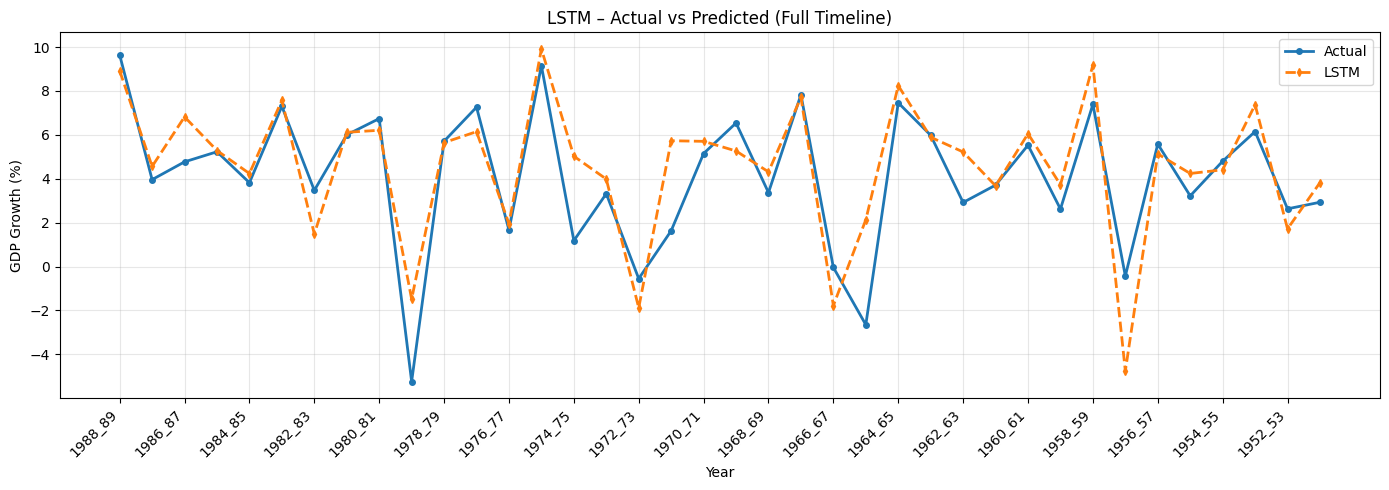

In [55]:
lstm_model.eval()
lstm_pred_scaled = []

with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(DEVICE)
        pred = lstm_model(xb)
        lstm_pred_scaled.extend(pred.cpu().numpy().flatten())

lstm_pred_scaled = np.array(lstm_pred_scaled)

# inverse-transform to original GDP scale
lstm_train_rmse = rmse(y_train_dl_unscaled, y_pred_lstm_train)
lstm_test_actual = TARGET_SCALER.inverse_transform(
    y_test_dl.reshape(-1, 1)
).flatten()
lstm_pred = TARGET_SCALER.inverse_transform(
    lstm_pred_scaled.reshape(-1, 1)
).flatten()

comparison_lstm = pd.DataFrame([{
    'Model': 'LSTM',
    'RMSE_train': round(lstm_train_rmse, 4),
    'RMSE_test': round(rmse(lstm_test_actual, lstm_pred), 4),
    **evaluate_metrics(lstm_test_actual, lstm_pred)
}])

print("LSTM: FULL DL test years (len =", len(years_dl), ")")
display(comparison_lstm)
comparison_lstm.to_csv('lstm_full_years.csv', index=False)

# Actual vs Predicted
plt.figure(figsize=(14,5))
plt.plot(years_dl, lstm_test_actual, 'o-', label='Actual', linewidth=2, markersize=4)
plt.plot(years_dl, lstm_pred, 'd--', label='LSTM', linewidth=2, markersize=4)

step = 2
plt.xticks(range(0, len(years_dl), step),
           years_dl[::step],
           rotation=45, ha='right')

plt.xlabel('Year')
plt.ylabel('GDP Growth (%)')
plt.title('LSTM – Actual vs Predicted (Full Timeline)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('lstm_full_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

**Transformer Train**

In [44]:
transformer_model = TransformerModel(input_size=input_size, d_model=64, nhead=4, num_layers=2, dim_feedforward=128, dropout=0.2)
print('Training Transformer...')
transformer_model = train_model_torch(transformer_model, train_loader, test_loader, lr=1e-3, epochs=1000, patience=40, device=DEVICE)
torch.save(transformer_model.state_dict(), 'pytorch_transformer.pt')
print('Saved pytorch_transformer.pt')

Training Transformer...
Epoch 1/1000 Train loss: 0.097534 | Test loss: 0.067681
Epoch 2/1000 Train loss: 0.044282 | Test loss: 0.040094
Epoch 3/1000 Train loss: 0.046131 | Test loss: 0.062246
Epoch 4/1000 Train loss: 0.042305 | Test loss: 0.040822
Epoch 5/1000 Train loss: 0.045486 | Test loss: 0.046705
Epoch 6/1000 Train loss: 0.044344 | Test loss: 0.039998
Epoch 7/1000 Train loss: 0.038921 | Test loss: 0.054320
Epoch 8/1000 Train loss: 0.041151 | Test loss: 0.040172
Epoch 9/1000 Train loss: 0.045032 | Test loss: 0.040949
Epoch 10/1000 Train loss: 0.035987 | Test loss: 0.046907
Epoch 11/1000 Train loss: 0.041150 | Test loss: 0.058075
Epoch 12/1000 Train loss: 0.042134 | Test loss: 0.061172
Epoch 13/1000 Train loss: 0.043301 | Test loss: 0.041138
Epoch 14/1000 Train loss: 0.042613 | Test loss: 0.049459
Epoch 15/1000 Train loss: 0.041977 | Test loss: 0.054592
Epoch 16/1000 Train loss: 0.040552 | Test loss: 0.066584
Epoch 17/1000 Train loss: 0.045528 | Test loss: 0.067638
Epoch 18/1000 Tr

Transformer: FULL DL test years (len = 38 )


,Model,RMSE_train,RMSE_test,MAE,RMSE,R2
0,Transformer,0.6984,1.1617,0.8481,1.1617,0.8611


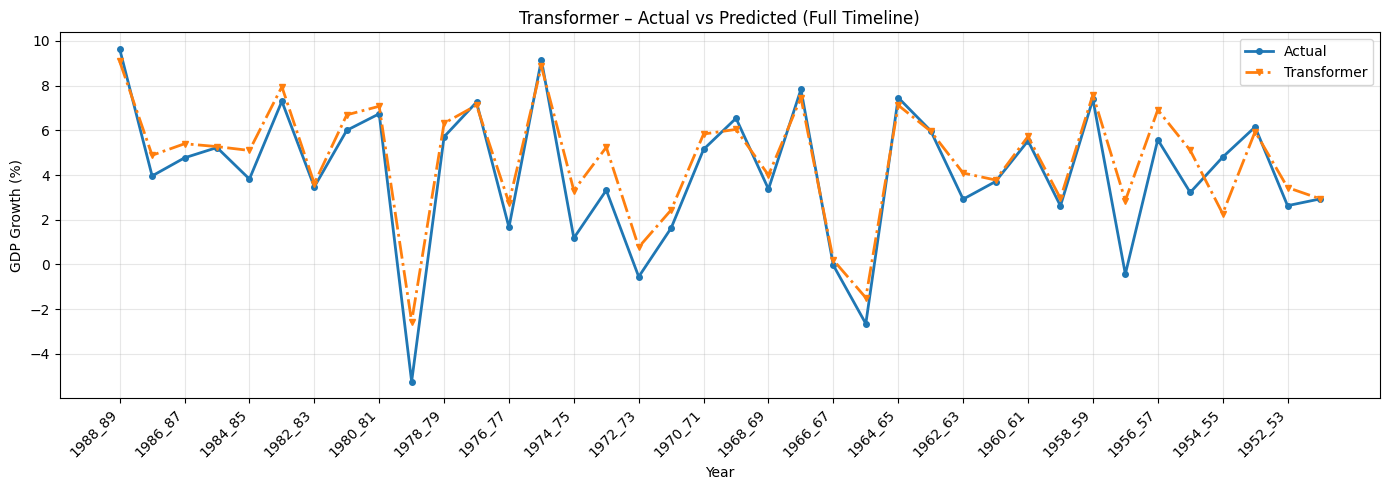

In [56]:
transformer_model.eval()
transformer_pred_scaled = []

with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(DEVICE)
        pred = transformer_model(xb)
        transformer_pred_scaled.extend(pred.cpu().numpy().flatten())

transformer_pred_scaled = np.array(transformer_pred_scaled)

trans_train_rmse = rmse(y_train_dl_unscaled, y_pred_trans_train)
transformer_test_actual = TARGET_SCALER.inverse_transform(
    y_test_dl.reshape(-1, 1)
).flatten()
transformer_pred = TARGET_SCALER.inverse_transform(
    transformer_pred_scaled.reshape(-1, 1)
).flatten()

comparison_transformer = pd.DataFrame([{
    'Model': 'Transformer',
    'RMSE_train': round(trans_train_rmse, 4),
    'RMSE_test': round(rmse(transformer_test_actual, transformer_pred), 4),
    **evaluate_metrics(transformer_test_actual, transformer_pred)
}])

print("Transformer: FULL DL test years (len =", len(years_dl), ")")
display(comparison_transformer)
comparison_transformer.to_csv('transformer_full_years.csv', index=False)

# Actual vs Predicted
plt.figure(figsize=(14,5))
plt.plot(years_dl, transformer_test_actual, 'o-', label='Actual', linewidth=2, markersize=4)
plt.plot(years_dl, transformer_pred, 'v-.', label='Transformer', linewidth=2, markersize=4)

step = 2
plt.xticks(range(0, len(years_dl), step),
           years_dl[::step],
           rotation=45, ha='right')

plt.xlabel('Year')
plt.ylabel('GDP Growth (%)')
plt.title('Transformer – Actual vs Predicted (Full Timeline)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('transformer_full_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Predictions & Evaluation (DL)
- We predict on the DL test set.
- We invert the target scaler to get GDP in original units.
- Compute MAE, RMSE, R² on DL test set.

In [47]:
def predict_torch(model, X, device=DEVICE, batch_size=64):
    model.eval()
    ds = SeqDataset(X, np.zeros((len(X),)))
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False)
    preds = []
    with torch.no_grad():
        for xb,_ in loader:
            xb = xb.to(device)
            out = model(xb).cpu().numpy().reshape(-1)
            preds.append(out)
    return np.concatenate(preds, axis=0)

# LSTM: train preds scaled -> inverse, test preds scaled -> inverse
y_pred_lstm_train_scaled = predict_torch(lstm_model, X_train_dl)
y_pred_lstm_test_scaled = predict_torch(lstm_model, X_test_dl)
y_pred_lstm_train = TARGET_SCALER.inverse_transform(y_pred_lstm_train_scaled.reshape(-1,1)).reshape(-1)
y_pred_lstm_test = TARGET_SCALER.inverse_transform(y_pred_lstm_test_scaled.reshape(-1,1)).reshape(-1)
y_train_dl_unscaled = TARGET_SCALER.inverse_transform(y_train_dl.reshape(-1,1)).reshape(-1)
y_test_dl_unscaled = TARGET_SCALER.inverse_transform(y_test_dl.reshape(-1,1)).reshape(-1)

# Metrics LSTM
metrics_lstm_train = { 'RMSE_train': rmse(y_train_dl_unscaled, y_pred_lstm_train)}
metrics_lstm_test = evaluate_metrics(y_test_dl_unscaled, y_pred_lstm_test)
print('LSTM TRAIN RMSE:', metrics_lstm_train['RMSE_train'])
print('LSTM TEST metrics:', metrics_lstm_test)

# Transformer
y_pred_trans_train_scaled = predict_torch(transformer_model, X_train_dl)
y_pred_trans_test_scaled = predict_torch(transformer_model, X_test_dl)
y_pred_trans_train = TARGET_SCALER.inverse_transform(y_pred_trans_train_scaled.reshape(-1,1)).reshape(-1)
y_pred_trans_test = TARGET_SCALER.inverse_transform(y_pred_trans_test_scaled.reshape(-1,1)).reshape(-1)

metrics_trans_train = {'RMSE_train': rmse(y_train_dl_unscaled, y_pred_trans_train)}
metrics_trans_test = evaluate_metrics(y_test_dl_unscaled, y_pred_trans_test)
print('\nTransformer TRAIN RMSE:', metrics_trans_train['RMSE_train'])
print('Transformer TEST metrics:', metrics_trans_test)

LSTM TRAIN RMSE: 1.1319170339395075
LSTM TEST metrics: {'MAE': 1.2613, 'RMSE': np.float64(1.7919), 'R2': 0.6695}

Transformer TRAIN RMSE: 0.6984046160234054
Transformer TEST metrics: {'MAE': 0.8481, 'RMSE': np.float64(1.1617), 'R2': 0.8611}


## 7. Final comparison: align ML predictions to the DL-test calendar years
We compute ML model predictions for the ML test period, then restrict ML test predictions to the DL test years (intersection) so all 4 models are compared on identical calendar years. We then compute MAE, RMSE, R² for each model on the intersection years and present a table and plots.

Years compared: ['1988_89', '1987_88', '1986_87', '1985_86', '1984_85', '1983_84', '1982_83', '1981_82', '1980_81', '1979_80', '1978_79', '1977_78', '1976_77', '1975_76', '1974_75', '1973_74', '1972_73', '1971_72', '1970_71', '1969_70', '1968_69', '1967_68', '1966_67', '1965_66', '1964_65', '1963_64', '1962_63', '1961_62', '1960_61', '1959_60', '1958_59', '1957_58', '1956_57', '1955_56', '1954_55', '1953_54', '1952_53', '1951_52']


,Model,RMSE_train,RMSE_test,MAE,RMSE,R2
0,Polynomial Regression,1.133098,1.273127,1.0664,1.2731,0.8332
1,XGBoost,0.161494,0.769511,0.5047,0.7695,0.9391
2,LSTM,1.131917,1.791903,1.2613,1.7919,0.6695
3,Transformer,0.698405,1.161732,0.8481,1.1617,0.8611


<Figure size 1000x600 with 0 Axes>

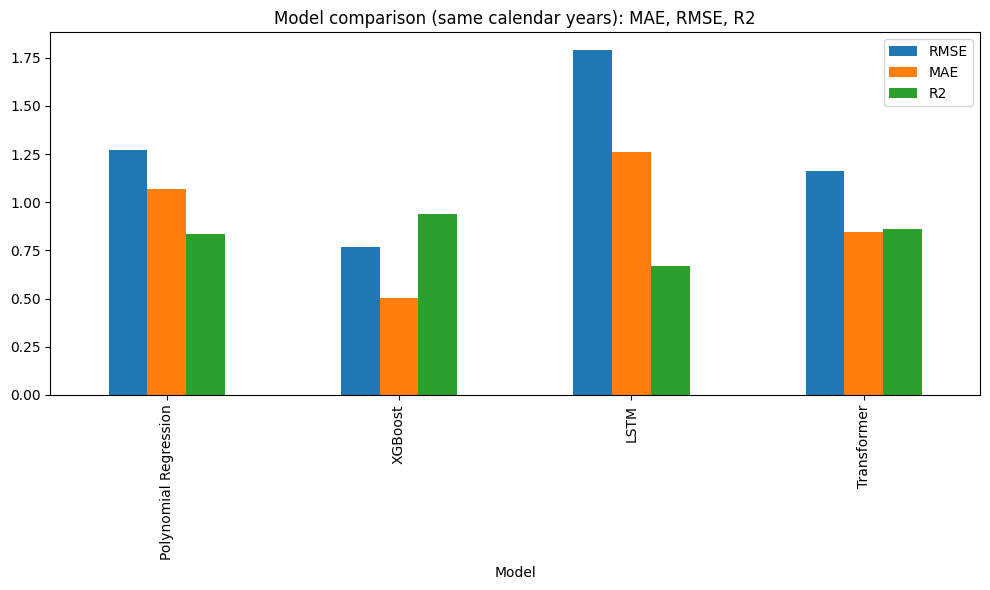

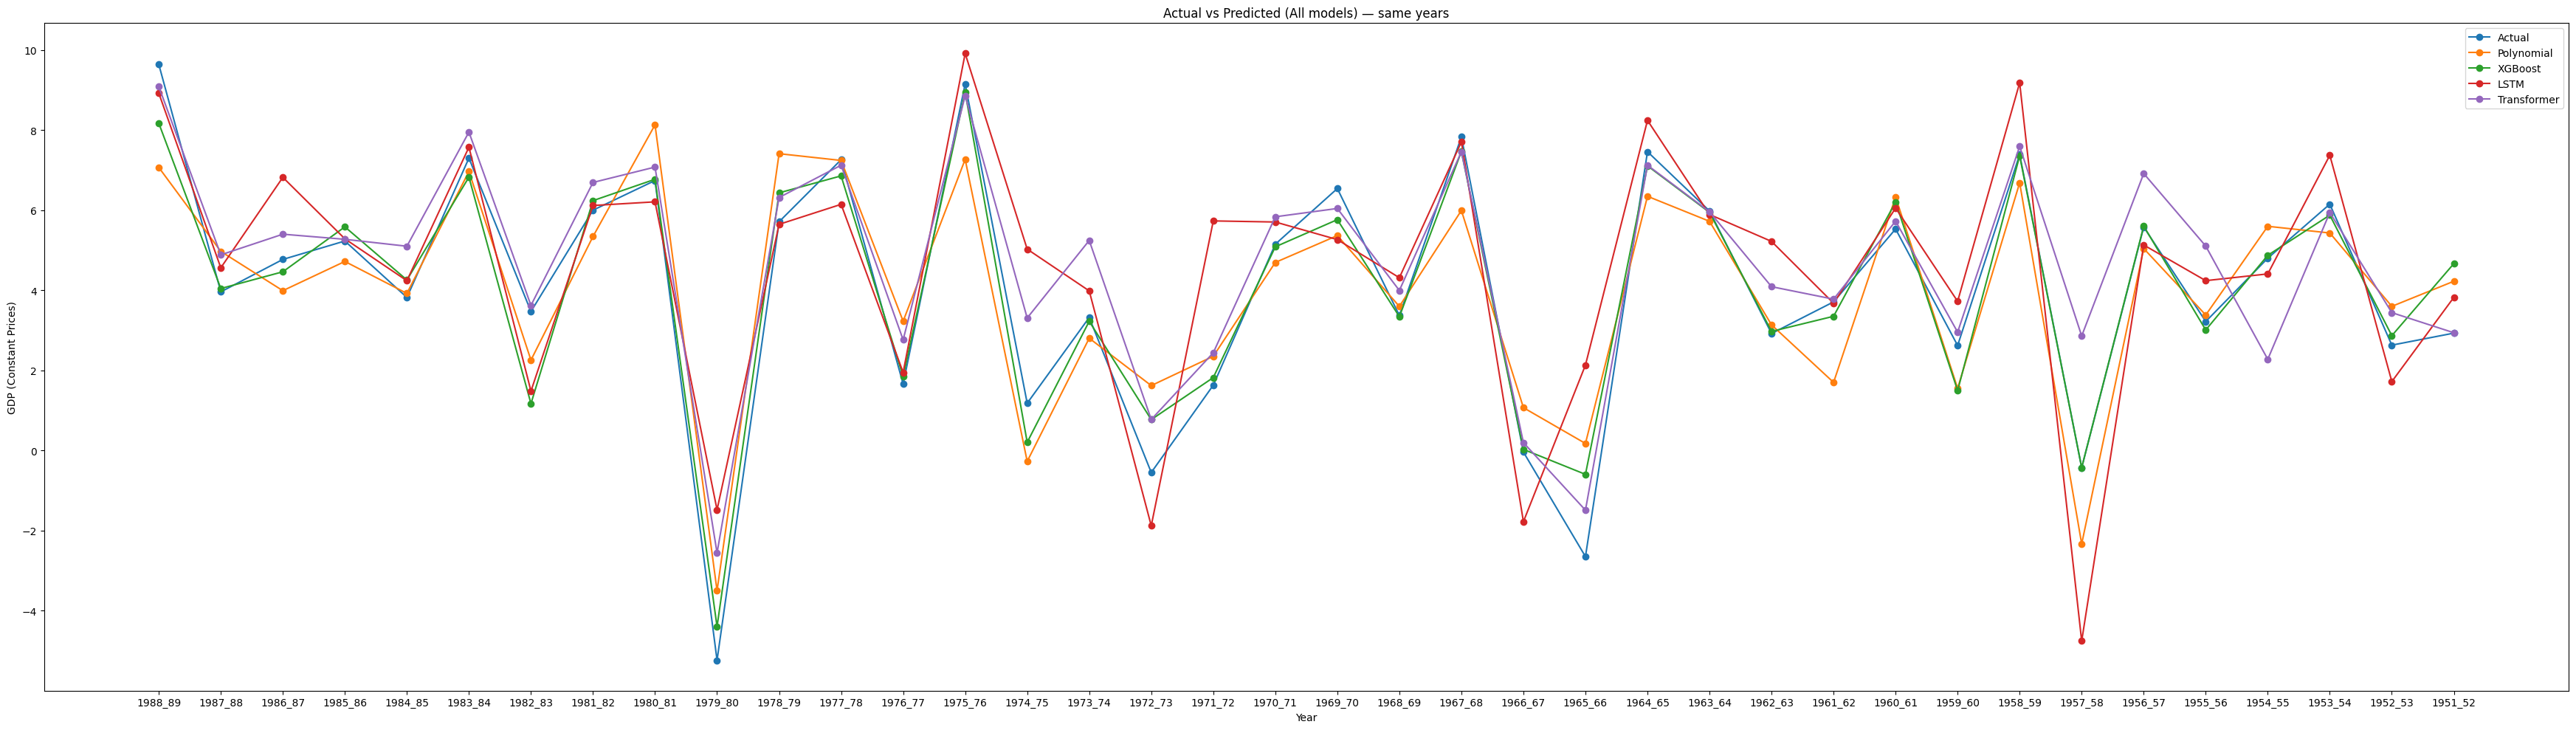

In [54]:
# Intersection years as before
years_ml_list = list(years_ml)
years_dl_list = list(years_dl)
intersect_indices_in_ml = [i for i,yv in enumerate(years_ml_list) if yv in years_dl_list]
intersect_years = [years_ml_list[i] for i in intersect_indices_in_ml]

# ML: train RMSE on ML training set, test RMSE on intersection years
poly_train_rmse = rmse(y_train, poly_train_pred)
xgb_train_rmse = rmse(y_train, xgb_train_pred)

ml_actual_on_intersect = y_test[intersect_indices_in_ml]
ml_poly_on_intersect = poly_pred[intersect_indices_in_ml]
ml_xgb_on_intersect = xgb_pred[intersect_indices_in_ml]

poly_test_rmse_on_intersect = rmse(ml_actual_on_intersect, ml_poly_on_intersect)
xgb_test_rmse_on_intersect = rmse(ml_actual_on_intersect, ml_xgb_on_intersect)

# DL: train RMSE already computed above, test RMSE on intersection years (aligned)
dl_year_to_idx = {y: idx for idx,y in enumerate(years_dl_list)}
dl_indices_aligned = [dl_year_to_idx[y] for y in intersect_years]
dl_lstm_on_intersect = y_pred_lstm_test[dl_indices_aligned]  #
dl_trans_on_intersect = y_pred_trans_test[dl_indices_aligned]

# DL train RMSEs
lstm_train_rmse = rmse(y_train_dl_unscaled, y_pred_lstm_train)
trans_train_rmse = rmse(y_train_dl_unscaled, y_pred_trans_train)

# DL test RMSEs on intersection
lstm_test_rmse_on_intersect = rmse(ml_actual_on_intersect, dl_lstm_on_intersect)
trans_test_rmse_on_intersect = rmse(ml_actual_on_intersect, dl_trans_on_intersect)

comparison_rows = [
    {'Model':'Polynomial Regression', 'RMSE_train': poly_train_rmse, 'RMSE_test': poly_test_rmse_on_intersect, **evaluate_metrics(ml_actual_on_intersect, ml_poly_on_intersect)},
    {'Model':'XGBoost', 'RMSE_train': xgb_train_rmse, 'RMSE_test': xgb_test_rmse_on_intersect, **evaluate_metrics(ml_actual_on_intersect, ml_xgb_on_intersect)},
    {'Model':'LSTM', 'RMSE_train': lstm_train_rmse, 'RMSE_test': lstm_test_rmse_on_intersect, **evaluate_metrics(ml_actual_on_intersect, dl_lstm_on_intersect)},
    {'Model':'Transformer', 'RMSE_train': trans_train_rmse, 'RMSE_test': trans_test_rmse_on_intersect, **evaluate_metrics(ml_actual_on_intersect, dl_trans_on_intersect)},
]

comparison_df = pd.DataFrame(comparison_rows)
print('Years compared:', intersect_years)
display(comparison_df)
comparison_df.to_csv('comparison_with_train_test_rmse.csv', index=False)

# Plots
plt.figure(figsize=(10,6))
comparison_df_plot = comparison_df.set_index('Model')[['RMSE','MAE','R2']]
comparison_df_plot.plot(kind='bar', figsize=(10,6))
plt.title('Model comparison (same calendar years): MAE, RMSE, R2')
plt.tight_layout()
plt.savefig('comparison_metrics_bar_colab.png', dpi=150)
plt.show()

# Actual vs Predictions plot (same years)
plt.figure(figsize=(35,10))
yrs = intersect_years
plt.plot(yrs, ml_actual_on_intersect, marker='o', label='Actual')
plt.plot(yrs, ml_poly_on_intersect, marker='o', label='Polynomial')
plt.plot(yrs, ml_xgb_on_intersect, marker='o', label='XGBoost')
plt.plot(yrs, dl_lstm_on_intersect, marker='o', label='LSTM')
plt.plot(yrs, dl_trans_on_intersect, marker='o', label='Transformer')
plt.xlabel('Year'); plt.ylabel('GDP (Constant Prices)')
plt.title('Actual vs Predicted (All models) — same years')
plt.legend(); plt.tight_layout()
plt.savefig('actual_vs_pred_same_years_colab.png', dpi=200)
plt.show()

## 8. Save models
- Saved files: `polynomial_pipeline.joblib`, `xgboost_model.joblib`, `pytorch_lstm.pt`, `pytorch_transformer.pt`, scalers, CSV, and plots.

In [49]:
print('Saved files (if training completed):')
for f in ['polynomial_pipeline.joblib','xgboost_model.joblib','pytorch_lstm.pt','pytorch_transformer.pt',
          'scaler_ml.joblib','scaler_features_dl.joblib','scaler_target_dl.joblib','comparison_with_train_test_rmse.csv']:
    print('-', f, os.path.exists(f))

Saved files (if training completed):
- polynomial_pipeline.joblib True
- xgboost_model.joblib True
- pytorch_lstm.pt True
- pytorch_transformer.pt True
- scaler_ml.joblib True
- scaler_features_dl.joblib True
- scaler_target_dl.joblib True
- comparison_with_train_test_rmse.csv True


# Predict the Next year GDP Growth in `%` by entering the value for asked features





In [50]:
import numpy as np
import joblib
import torch

def safe_load(name, filepath, loader_fn):
    if name in globals():
        return globals()[name]
    try:
        return loader_fn(filepath)
    except Exception as e:
        print(f"Could not load {name} from {filepath}: {e}")
        return None

poly_pipeline = safe_load('poly_pipeline', 'polynomial_pipeline.joblib', lambda p: joblib.load(p))
xgb_model      = safe_load('xgb_model', 'xgboost_model.joblib', lambda p: joblib.load(p))
scaler_ml      = safe_load('scaler_ml', 'scaler_ml.joblib', lambda p: joblib.load(p))
FEATURE_SCALER = safe_load('FEATURE_SCALER', 'scaler_features_dl.joblib', lambda p: joblib.load(p))
TARGET_SCALER  = safe_load('TARGET_SCALER', 'scaler_target_dl.joblib', lambda p: joblib.load(p))

def try_load_torch_model(name, path, model_ctor):
    if name in globals():
        return globals()[name]
    if os.path.exists(path):
        m = model_ctor()
        m.load_state_dict(torch.load(path, map_location='cpu'))
        m.eval()
        return m
    else:
        print(f"{path} not found — skipping {name}.")
        return None

need_lstm = 'lstm_model' not in globals()
need_trans = 'transformer_model' not in globals()

if need_lstm:
    try:
        lstm_model = try_load_torch_model('lstm_model', 'pytorch_lstm.pt',
                                         lambda: LSTMModel(input_size=len(feature_cols), hidden_size=64, num_layers=1, dropout=0.2))
    except NameError:
        lstm_model = None
else:
    lstm_model = globals()['lstm_model']

if need_trans:
    try:
        transformer_model = try_load_torch_model('transformer_model', 'pytorch_transformer.pt',
                                                 lambda: TransformerModel(input_size=len(feature_cols), d_model=64, nhead=4, num_layers=2, dim_feedforward=128, dropout=0.2))
    except NameError:
        transformer_model = None
else:
    transformer_model = globals()['transformer_model']

print("Enter values for the following features in this order:")
print(", ".join(feature_cols))
print("Enter numeric values (no commas). Press Enter after each.")

user_vals = []
for feat in feature_cols:
    while True:
        v = input(f"{feat}: ").strip()
        try:
            fv = float(v)
            user_vals.append(fv)
            break
        except:
            print("Please enter a valid numeric value (e.g., 5.3).")

user_array = np.array(user_vals, dtype=float).reshape(1, -1)  # shape (1, n_features)

results = {}

# 1) Polynomial Regression
if poly_pipeline is not None:
    try:
        pred_poly = poly_pipeline.predict(user_array.reshape(1, -1)).reshape(-1)[0]
        results['Polynomial Regression'] = float(pred_poly)
    except Exception as e:
        print("Poly prediction failed:", e)

# 2) XGBoost
if xgb_model is not None and scaler_ml is not None:
    try:
        user_scaled_ml = scaler_ml.transform(user_array)  # (1, n_features)
        pred_xgb = xgb_model.predict(user_scaled_ml).reshape(-1)[0]
        results['XGBoost'] = float(pred_xgb)
    except Exception as e:
        print("XGBoost prediction failed:", e)

# 3 & 4) DL (LSTM / Transformer)
def make_dl_sequence(user_array, features_scaled_all, LOOKBACK):
    if LOOKBACK <= 1:
        seq = user_array.astype(np.float32).reshape(1, 1, -1)
    else:
        hist = features_scaled_all[-(LOOKBACK-1):, :] if features_scaled_all.shape[0] >= (LOOKBACK-1) else features_scaled_all
        if hist.shape[0] < (LOOKBACK-1):
            pad_needed = (LOOKBACK-1) - hist.shape[0]
            pad = np.repeat(hist[:1, :], pad_needed, axis=0)
            hist = np.vstack([pad, hist])
        user_scaled = FEATURE_SCALER.transform(user_array)
        seq = np.vstack([hist, user_scaled])
        seq = seq.reshape(1, seq.shape[0], seq.shape[1]).astype(np.float32)
    return seq

try:
    features_scaled_all
except NameError:
    if 'FEATURE_SCALER' in globals() and 'df' in globals():
        features_all = df[feature_cols].values.astype(np.float32)
        features_scaled_all = FEATURE_SCALER.transform(features_all)
    else:
        features_scaled_all = None

if FEATURE_SCALER is None:
    print("FEATURE_SCALER not available — DL predictions will be skipped.")
else:
    seq = make_dl_sequence(user_array, features_scaled_all, LOOKBACK)

    # LSTM
    if lstm_model is not None:
        try:
            lstm_model = lstm_model.to(DEVICE)
            lstm_model.eval()
            with torch.no_grad():
                x_input = torch.tensor(seq, dtype=torch.float32).to(DEVICE)
                out = lstm_model(x_input).cpu().numpy().reshape(-1)[0]
            pred_lstm = TARGET_SCALER.inverse_transform(np.array([[out]])).reshape(-1)[0]
            results['LSTM'] = float(pred_lstm)
        except Exception as e:
            print("LSTM prediction failed:", e)

    # Transformer
    if transformer_model is not None:
        try:
            transformer_model = transformer_model.to(DEVICE)
            transformer_model.eval()
            with torch.no_grad():
                x_input = torch.tensor(seq, dtype=torch.float32).to(DEVICE)
                out = transformer_model(x_input).cpu().numpy().reshape(-1)[0]
            pred_trans = TARGET_SCALER.inverse_transform(np.array([[out]])).reshape(-1)[0]
            results['Transformer'] = float(pred_trans)
        except Exception as e:
            print("Transformer prediction failed:", e)

print("\nPredicted NEXT YEAR GDP Growth Rate:")
for model_name, val in results.items():
    print(f"{model_name}: {val:.4f}")

if not results:
    print("No predictions were produced. Check that models and scalers are loaded and defined.")

Enter values for the following features in this order:
Private Final Consumption Expenditure__Constant Prices, Government Final Consumption Expenditure__Constant Prices, Gross Fixed Capital Formation__Constant Prices, Changes in Stocks__Constant Prices, Exports of Goods and Services__Constant Prices, Import of Goods and Services__Constant Prices
Enter numeric values (no commas). Press Enter after each.
Private Final Consumption Expenditure__Constant Prices: 5.56
Government Final Consumption Expenditure__Constant Prices: 8.14
Gross Fixed Capital Formation__Constant Prices: 8.78
Changes in Stocks__Constant Prices: 53.44
Exports of Goods and Services__Constant Prices: 2.2
Import of Goods and Services__Constant Prices: 13.75

Predicted NEXT YEAR GDP Growth Rate:
Polynomial Regression: 6.3554
XGBoost: 8.4797
LSTM: 6.8490
Transformer: 2.4573


# Convert Predicted GDP Growth Rate (%) → Next Year GDP Amount

In [51]:

print("\nConvert Predicted Growth Rate (%) to Actual GDP Amount")

# Example: 3.6 for $3.6 trillion, or 203 for 203 lakh crore INR
while True:
    try:
        last_year_gdp = float(input("Enter LAST year's GDP amount (in your preferred units): "))
        break
    except:
        print("Please enter a valid number (e.g., 3.5 or 230 or 360000).")

converted_results = {}

for model_name, growth_rate in results.items():
    growth_decimal = growth_rate / 100.0

    next_year_gdp = last_year_gdp * (1 + growth_decimal)

    converted_results[model_name] = next_year_gdp

print("\nPredicted GDP Amount for Next Year:")
for model_name, gdp_value in converted_results.items():
    print(f"{model_name}: {gdp_value:.4f}  (same units as input)")



Convert Predicted Growth Rate (%) to Actual GDP Amount
Enter LAST year's GDP amount (in your preferred units): 173

Predicted GDP Amount for Next Year:
Polynomial Regression: 183.9949  (same units as input)
XGBoost: 187.6699  (same units as input)
LSTM: 184.8488  (same units as input)
Transformer: 177.2512  (same units as input)
